# Bank Customer Segmentation and Credit Risk: Part 4, Credit Risk

The final question of the project: **can the bank predict which loans will go bad, using only what it knew when it granted the loan?**

**The one rule for this notebook:** every feature must be calculated from data **before the loan date**. In notebook 02 I found that every bad loan went with a negative balance, but for most of them the balance only went negative *after* the loan, as a consequence of struggling to repay. Using anything from after the loan date would let the model "see the future" (**data leakage**) and make it look far better than it could ever be in real use.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold, RepeatedStratifiedKFold, cross_validate, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, precision_recall_curve

## 1. The loans

In [2]:
loans = pd.read_parquet("data/clean/loan.parquet").rename(columns={"date": "loan_date"})
trans = pd.read_parquet("data/clean/trans.parquet")
daily_balance = pd.read_parquet("data/clean/daily_balance.parquet")
segments = pd.read_parquet("data/clean/segments.parquet")

print(f"loans: {len(loans)}, bad: {loans['is_bad'].sum()} ({loans['is_bad'].mean():.1%})")
loans[["loan_id", "account_id", "loan_date", "amount", "duration", "payments", "status_label", "is_bad"]].head()

loans: 682, bad: 76 (11.1%)


,loan_id,account_id,loan_date,amount,duration,payments,status_label,is_bad
0,5314,1787,1993-07-05,96396,12,8033.0,"finished, not paid",True
1,5316,1801,1993-07-11,165960,36,4610.0,"finished, paid",False
2,6863,9188,1993-07-28,127080,60,2118.0,"finished, paid",False
3,5325,1843,1993-08-03,105804,36,2939.0,"finished, paid",False
4,7240,11013,1993-09-06,274740,60,4579.0,"finished, paid",False


682 loans, of which 76 (11%) are bad. That is a small dataset with an **imbalanced** target: a model that predicted "good" for every loan would be 89% accurate and completely useless. So accuracy is not a useful measure here (more on the measures in section 5).

### Do the newest loans have complete labels?

In [3]:
by_year = loans.groupby(loans["loan_date"].dt.year).agg(loans=("is_bad", "size"), bad=("is_bad", "sum"))
by_year["pct_bad"] = (100 * by_year["bad"] / by_year["loans"]).round(1)
by_year

,loans,bad,pct_bad
loan_date,,,
1993,20,4,20.0
1994,101,14,13.9
1995,90,12,13.3
1996,117,16,13.7
1997,196,26,13.3
1998,158,4,2.5


Loans granted in **1998** are bad only 2.5% of the time, against 10–14% in earlier years. That is unlikely to mean 1998 borrowers were safer: those loans had at most a year to go wrong before the data ends. Many of them are still running, and some will go bad later. Their "good" labels are **incomplete** (this is called **right-censoring**).

I keep the 1998 loans, because dropping them would lose almost a quarter of the data, but in section 7 I check that the results hold without them.

## 2. Features from before the loan

For each loan I look only at the account's history **before the loan date**, and build three kinds of features:

**How the customer used the account** (as in step 3: rates per month, leaving out January and bank-generated transactions):
- `months_history`, `trans_per_month`, `inflow_per_month`, `cash_share`, `receives_pension`, `pays_bills_by_transfer`

**Balances**, over the whole pre-loan history and in the **last 90 days before the loan**:
- `mean_balance`, `balance_std`, `negative_days`, `ever_negative`
- `recent_mean_balance`, `recent_min_balance`, `balance_change` (recent mean ÷ overall mean)

**The loan itself**, which the bank knows when it decides:
- `amount`, `duration`, `payments` (monthly payment)
- `payment_to_inflow`: monthly payment ÷ monthly income: can the customer afford it?
- `payment_to_balance`: monthly payment ÷ recent balance

**Deliberately left out:** age, gender and district. They added almost nothing in early tests, and using personal characteristics like gender or age to decide on credit raises fairness and, in many countries, legal problems.

In [4]:
loan_dates = loans[["account_id", "loan_date"]]

# only rows strictly before each account's loan date
pre_trans = trans.merge(loan_dates, on="account_id")
pre_trans = pre_trans[pre_trans["date"] < pre_trans["loan_date"]]

pre_balance = daily_balance.merge(loan_dates, on="account_id")
pre_balance = pre_balance[pre_balance["date"] < pre_balance["loan_date"]]

# leakage checks: nothing on or after the loan date, and no loan repayments yet
assert (pre_trans["date"] < pre_trans["loan_date"]).all()
assert (pre_balance["date"] < pre_balance["loan_date"]).all()
assert (pre_trans["purpose"] != "loan repayment").all()

print(f"pre-loan transactions: {len(pre_trans):,}")
print(f"pre-loan account-days: {len(pre_balance):,}")

pre-loan transactions: 54,694
pre-loan account-days: 42,671


In [5]:
features = loans.set_index("account_id")[["loan_id", "loan_date", "amount", "duration", "payments", "is_bad"]].copy()

first_transaction = trans.groupby("account_id")["date"].min()
features["months_history"] = (features["loan_date"] - first_transaction).dt.days / 30.44

# behaviour
bank_generated = ["interest credited", "statement fee", "penalty interest"]
behaviour = pre_trans[~pre_trans["purpose"].isin(bank_generated) & (pre_trans["date"].dt.month != 1)]
n_trans = behaviour.groupby("account_id").size()

features["trans_per_month"] = n_trans / features["months_history"]
features["inflow_per_month"] = (behaviour[behaviour["direction"] == "credit"]
                                .groupby("account_id")["amount"].sum() / features["months_history"])
features["cash_share"] = (behaviour[behaviour["operation"].isin(["cash deposit", "cash withdrawal"])]
                          .groupby("account_id").size() / n_trans)
features["receives_pension"] = features.index.isin(behaviour.loc[behaviour["purpose"] == "pension", "account_id"])
features["pays_bills_by_transfer"] = features.index.isin(behaviour.loc[behaviour["purpose"] == "household bills", "account_id"])
features[["trans_per_month", "inflow_per_month", "cash_share"]] = features[["trans_per_month", "inflow_per_month", "cash_share"]].fillna(0)

# balances: whole pre-loan history
balances = pre_balance.groupby("account_id")["end_of_day_balance"]
features["mean_balance"] = balances.mean()
features["balance_std"] = balances.std()
features["negative_days"] = pre_balance[pre_balance["end_of_day_balance"] < 0].groupby("account_id").size()
features["negative_days"] = features["negative_days"].fillna(0)
features["ever_negative"] = features["negative_days"] > 0

# balances: last 90 days before the loan
recent = pre_balance[pre_balance["date"] >= pre_balance["loan_date"] - pd.Timedelta(days=90)]
features["recent_mean_balance"] = recent.groupby("account_id")["end_of_day_balance"].mean()
features["recent_min_balance"] = recent.groupby("account_id")["end_of_day_balance"].min()
features["balance_change"] = features["recent_mean_balance"] / features["mean_balance"]

# affordability
features["payment_to_inflow"] = features["payments"] / features["inflow_per_month"]
# a recent balance near zero or negative would make this ratio meaningless (or negative),
# so the balance is floored at 100 CZK: a tiny balance then gives a very large ratio, as it should
features["payment_to_balance"] = features["payments"] / features["recent_mean_balance"].clip(lower=100)

print("missing values:", features.isna().sum().sum())
features.head()

missing values: 0


,loan_id,loan_date,amount,duration,payments,is_bad,months_history,trans_per_month,inflow_per_month,cash_share,...,pays_bills_by_transfer,mean_balance,balance_std,negative_days,ever_negative,recent_mean_balance,recent_min_balance,balance_change,payment_to_inflow,payment_to_balance
account_id,,,,,,,,,,,,,,,,,,,,,
1787,5314,1993-07-05,96396,12,8033.0,True,3.449409,1.159619,5827.085714,1.000000,...,False,12250.000000,8330.866301,0.0,False,15966.666667,11000.0,1.303401,1.378562,0.503111
1801,5316,1993-07-11,165960,36,4610.0,False,4.862024,5.964595,47110.219189,0.724138,...,True,50742.077419,26771.688798,0.0,False,52986.050000,23795.0,1.044223,0.097856,0.087004
9188,6863,1993-07-28,127080,60,2118.0,False,5.584757,2.864941,13322.871765,0.500000,...,True,28652.561111,11376.586144,0.0,False,34106.466667,20272.8,1.190346,0.158975,0.062100
1843,5325,1993-08-03,105804,36,2939.0,False,6.077530,2.797189,19499.370378,0.529412,...,True,41383.971429,15306.108995,0.0,False,47746.078571,34129.2,1.153734,0.150723,0.061555
11013,7240,1993-09-06,274740,60,4579.0,False,6.701708,2.835098,41062.067843,0.526316,...,True,52361.985714,20562.993927,0.0,False,53563.390909,40960.1,1.022944,0.111514,0.085487


In [6]:
feature_cols = ["months_history", "trans_per_month", "inflow_per_month", "cash_share",
                "receives_pension", "pays_bills_by_transfer",
                "mean_balance", "balance_std", "negative_days", "ever_negative",
                "recent_mean_balance", "recent_min_balance", "balance_change",
                "amount", "duration", "payments", "payment_to_inflow", "payment_to_balance"]

X = features[feature_cols].astype(float)
y = features["is_bad"].astype(int).values
print(f"{X.shape[0]} loans × {X.shape[1]} features")

682 loans × 18 features


## 3. Which features separate good and bad loans?

A first look, one feature at a time. For each feature I compute the **ROC-AUC** it would get on its own: 0.5 means it can't tell good and bad loans apart at all, 1.0 means it separates them perfectly. (If a feature works "the wrong way round", for example lower balance means more risk, I flip it, so every value is between 0.5 and 1.)

In [7]:
single = pd.DataFrame({
    "median_good": X[y == 0].median(),
    "median_bad": X[y == 1].median(),
    "auc_alone": [max(roc_auc_score(y, X[c]), 1 - roc_auc_score(y, X[c])) for c in feature_cols],
}).sort_values("auc_alone", ascending=False)
single.round(3)

,median_good,median_bad,auc_alone
recent_min_balance,23794.050,8564.200,0.793
payment_to_balance,0.087,0.196,0.763
recent_mean_balance,42521.259,26014.777,0.736
cash_share,0.734,1.000,0.681
negative_days,0.000,0.000,0.678
ever_negative,0.000,0.000,0.678
payments,3799.000,5217.000,0.659
payment_to_inflow,0.153,0.175,0.657
balance_change,1.033,0.893,0.656
mean_balance,42461.644,36186.183,0.639


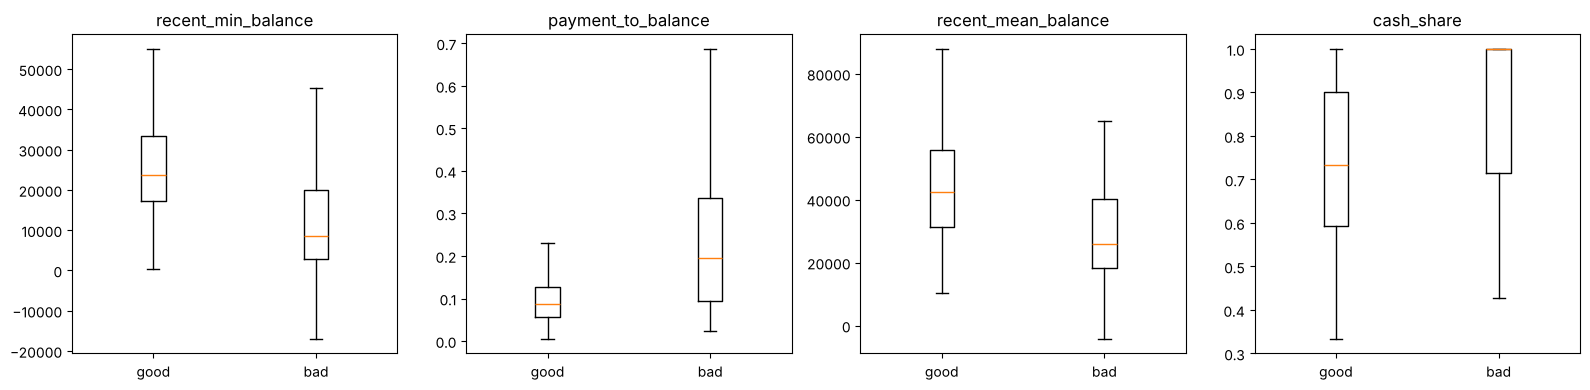

In [8]:
top = ["recent_min_balance", "payment_to_balance", "recent_mean_balance", "cash_share"]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, top):
    ax.boxplot([X.loc[y == 0, col], X.loc[y == 1, col]], showfliers=False)
    ax.set_xticks([1, 2], ["good", "bad"])
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [9]:
# bad-loan rate by quartile of the strongest features (Q1 = lowest 25% of values)
quartiles = {}
for col in top:
    q = pd.qcut(X[col].rank(method="first"), 4, labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"])
    quartiles[col] = (100 * pd.Series(y).groupby(q.values).mean()).round(1)
pd.DataFrame(quartiles).T

,Q1 (lowest),Q2,Q3,Q4 (highest)
recent_min_balance,31.0,4.7,5.9,2.9
payment_to_balance,4.1,6.5,6.5,27.5
recent_mean_balance,24.6,10.0,4.7,5.3
cash_share,6.4,7.6,4.7,25.7


The strongest single signals all describe **how much money the customer had just before asking for the loan**:
- **`recent_min_balance`** (the lowest balance in the last 90 days) is the best single feature (AUC 0.79). For bad loans its median is about 8,600 CZK, against about 23,800 CZK for good loans. Loans in the lowest quarter of this feature are bad **31%** of the time; the other three quarters, 3–6%.
- **`payment_to_balance`**: the monthly payment is a much bigger share of the recent balance for bad loans. The top quarter is bad 27.5% of the time.
- **`cash_share`**: the median bad-loan customer used **only cash** before the loan, against about 73% cash for good loans. The customers in the top quarter (the most cash-heavy) are bad 26% of the time.
- **`pays_bills_by_transfer`**: most good-loan customers paid household bills by transfer before the loan; most bad-loan customers didn't.

Weak or useless on their own: income (`inflow_per_month`), loan duration and receiving a pension. Interesting: bad-loan customers did **not** earn less than good-loan customers. What separates them is how they manage the money, not how much they have coming in.

## 4. A simple rule as a baseline

Before building a model, a simple rule to beat. From notebook 02: *never lend to an account that has been negative before.*

In [10]:
rule = X["ever_negative"].astype(bool).values
caught = (rule & (y == 1)).sum()
false_alarms = (rule & (y == 0)).sum()

print(f"loans refused by the rule: {rule.sum()}")
print(f"bad loans caught:          {caught} of {y.sum()} ({caught / y.sum():.0%})")
print(f"good loans refused:        {false_alarms}")

loans refused by the rule: 27
bad loans caught:          27 of 76 (36%)
good loans refused:        0


The rule is perfectly **precise** (it never refuses a good loan) but catches only about a third of the bad ones. A model has to catch more bad loans without refusing too many good ones.

## 5. Comparing models

Two models:
- **Logistic regression**: a straight-line model, simple and easy to explain. The features are scaled first, because logistic regression is sensitive to their units.
- **Random forest**: many decision trees voting together. It can pick up non-linear patterns (for example "risky only if the balance is low *and* the payment is high") and doesn't need scaling.

Both use `class_weight="balanced"`, which gives the 76 bad loans as much total weight in training as the 606 good ones, so the model doesn't just learn to say "good".

**How to measure them.** With only 682 loans, a single train/test split would leave about 15 bad loans in the test set, too few to trust. So I use **repeated stratified 5-fold cross-validation**: 5 folds, repeated 5 times with different shuffles, giving 25 scores per model. "Stratified" keeps 11% bad loans in every fold.

Two measures, both based on predicted probabilities:
- **ROC-AUC**: the chance that a randomly chosen bad loan gets a higher risk score than a randomly chosen good loan. 0.5 is guessing, 1.0 is perfect.
- **PR-AUC** (average precision): focuses on the bad loans only, which suits an imbalanced target better. Guessing scores about 0.11 here (the share of bad loans).

In [11]:
models = {
    "Logistic regression": make_pipeline(StandardScaler(),
                                         LogisticRegression(class_weight="balanced", C=0.3, max_iter=5000)),
    "Random forest": RandomForestClassifier(n_estimators=500, min_samples_leaf=5, class_weight="balanced",
                                            random_state=42, n_jobs=-1),
}

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=42)
cv_scores = {}
for name, model in models.items():
    result = cross_validate(model, X, y, cv=cv, scoring=["roc_auc", "average_precision"])
    cv_scores[name] = result

comparison = pd.DataFrame({
    name: {"ROC-AUC mean": r["test_roc_auc"].mean(), "ROC-AUC std": r["test_roc_auc"].std(),
           "PR-AUC mean": r["test_average_precision"].mean(), "PR-AUC std": r["test_average_precision"].std()}
    for name, r in cv_scores.items()
}).T
comparison.round(3)

,ROC-AUC mean,ROC-AUC std,PR-AUC mean,PR-AUC std
Logistic regression,0.882,0.045,0.695,0.096
Random forest,0.910,0.037,0.725,0.093


random forest better in 24 of 25 folds
average difference in ROC-AUC: 0.028


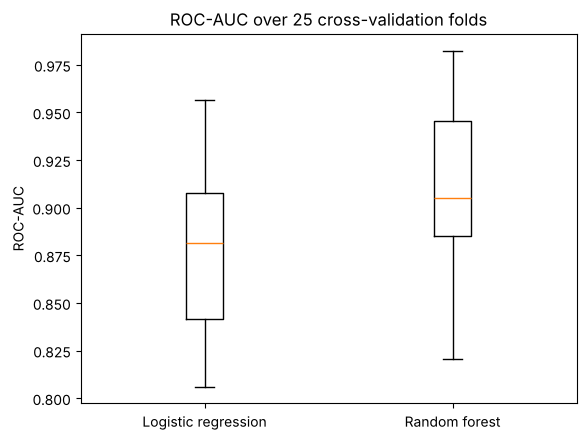

In [12]:
lr_auc = cv_scores["Logistic regression"]["test_roc_auc"]
rf_auc = cv_scores["Random forest"]["test_roc_auc"]

# the 25 folds are the same for both models, so they can be compared fold by fold
print(f"random forest better in {(rf_auc > lr_auc).sum()} of 25 folds")
print(f"average difference in ROC-AUC: {(rf_auc - lr_auc).mean():.3f}")

plt.boxplot([lr_auc, rf_auc])
plt.xticks([1, 2], ["Logistic regression", "Random forest"])
plt.ylabel("ROC-AUC")
plt.title("ROC-AUC over 25 cross-validation folds")
plt.show()

- Both models are far better than guessing: ROC-AUC around 0.88–0.91, and PR-AUC around 0.70, against 0.11 for guessing.
- The **random forest** is better on average (ROC-AUC 0.910 against 0.882) and in **24 of the 25 folds**. Because both models were tested on exactly the same folds, this is a fair, like-for-like comparison, and a consistent advantage rather than luck.
- The spread between folds (standard deviation about 0.04) is a reminder that with 76 bad loans, any single score is uncertain by a few points.

## 6. A more realistic test: predicting the future

Cross-validation mixes loans from all years, so a model can be trained on 1997 loans and tested on 1995 loans. A bank can only ever learn from the past. So as a second check I train on loans granted **up to 1996** and test on loans granted in **1997**. (1998 is left out of this test because its labels are incomplete.)

In [13]:
loan_year = features["loan_date"].dt.year.values
train = loan_year <= 1996
test = loan_year == 1997
print(f"train: {train.sum()} loans ({y[train].sum()} bad)   test: {test.sum()} loans ({y[test].sum()} bad)")

time_results = {}
for name, model in models.items():
    model.fit(X[train], y[train])
    p = model.predict_proba(X[test])[:, 1]
    time_results[name] = {"ROC-AUC": roc_auc_score(y[test], p), "PR-AUC": average_precision_score(y[test], p)}
pd.DataFrame(time_results).T.round(3)

train: 328 loans (46 bad)   test: 196 loans (26 bad)


,ROC-AUC,PR-AUC
Logistic regression,0.919,0.767
Random forest,0.904,0.669


Trained only on the past, both models still predict 1997's loans well: ROC-AUC 0.90–0.92. So the model isn't relying on mixing years, and the patterns hold over time.

Here logistic regression is slightly ahead of the random forest, the opposite of the cross-validation result. But this test has only 26 bad loans, so a difference of 0.015 is well within the noise; the 25-fold comparison is the stronger evidence. I choose the **random forest**, and note that logistic regression is a close, simpler alternative: if a bank needed to explain every decision line by line, its slightly lower accuracy might be worth it.

## 7. Checking the censoring problem

The 1998 loans have incomplete labels (section 1). If they were confusing the model, results without them would be noticeably different.

In [14]:
before_1998 = loan_year < 1998
rf = models["Random forest"]
without_1998 = cross_validate(rf, X[before_1998], y[before_1998], cv=cv, scoring="roc_auc")["test_score"]

print(f"random forest, all loans:      ROC-AUC {rf_auc.mean():.3f}")
print(f"random forest, without 1998:   ROC-AUC {without_1998.mean():.3f}")

random forest, all loans:      ROC-AUC 0.910
random forest, without 1998:   ROC-AUC 0.907


The result is almost the same without the 1998 loans, so the incomplete labels are not distorting the model.

## 8. What drives the predictions?

A random forest has no simple coefficients, so I use **permutation importance**: shuffle one feature's values in the test data and measure how much the ROC-AUC drops. If the model relies on a feature, scrambling it hurts; if not, nothing changes. I do this on the test fold of each of 5 folds, so the importance is measured on loans the model hasn't seen.

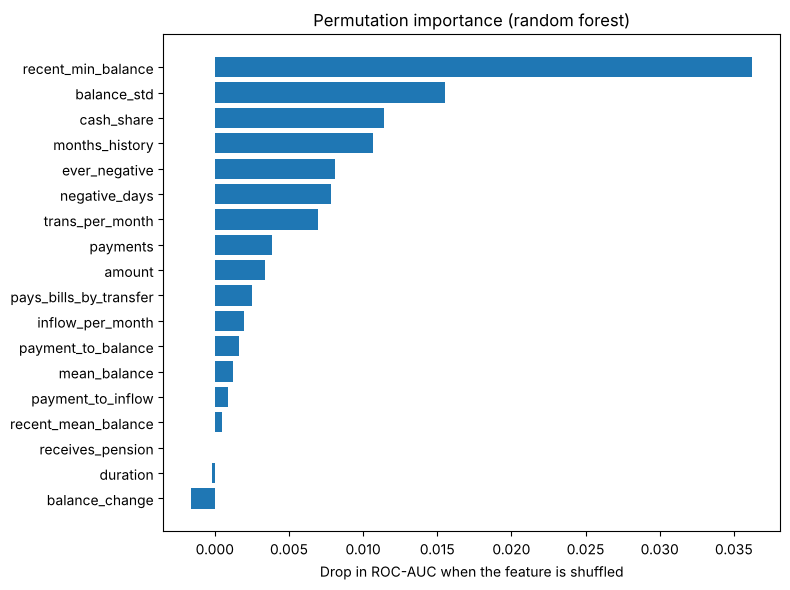

In [15]:
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
importances = []
for train_idx, test_idx in folds.split(X, y):
    model = RandomForestClassifier(n_estimators=500, min_samples_leaf=5, class_weight="balanced",
                                   random_state=42, n_jobs=-1).fit(X.iloc[train_idx], y[train_idx])
    result = permutation_importance(model, X.iloc[test_idx], y[test_idx], scoring="roc_auc",
                                    n_repeats=10, random_state=42, n_jobs=-1)
    importances.append(result.importances_mean)

importance = pd.Series(np.mean(importances, axis=0), index=feature_cols).sort_values()

plt.figure(figsize=(8, 6))
plt.barh(importance.index, importance.values)
plt.xlabel("Drop in ROC-AUC when the feature is shuffled")
plt.title("Permutation importance (random forest)")
plt.tight_layout()
plt.show()

- By far the most important feature is **`recent_min_balance`**: how low the balance fell in the 90 days before the loan.
- Next: **`balance_std`** (how much the balance swings), **`cash_share`**, **`months_history`** (bad loans tend to come from shorter histories) and the **negative-balance** features.
- The loan terms (amount, payment) matter less than the customer's behaviour.

One thing to be careful about: `payment_to_balance` was the second-best feature on its own, but scores low here. That's because it mostly repeats information that `recent_min_balance` and the other balance features already give. Shuffling it alone barely hurts, because the model can get the same information elsewhere. Permutation importance **underestimates features that overlap with others**, so a low score doesn't mean a feature is useless.

**In plain words:** the model flags customers whose **balance dropped low just before they asked for a loan**, whose balance **swings a lot**, who **use only cash**, and who **have already gone negative**. That makes sense for a bank: a customer who is short of money right now, with no regular transfers, is a risky borrower.

## 9. Turning risk scores into decisions

The model gives each loan a probability of going bad. To make a decision, the bank needs a **threshold**: refuse (or look more closely at) any loan above it. A low threshold catches more bad loans but refuses more good customers; a high threshold does the opposite.

To evaluate thresholds fairly, I use **out-of-fold** predictions: each loan's score comes from a model that was trained without that loan.

out-of-fold ROC-AUC: 0.905


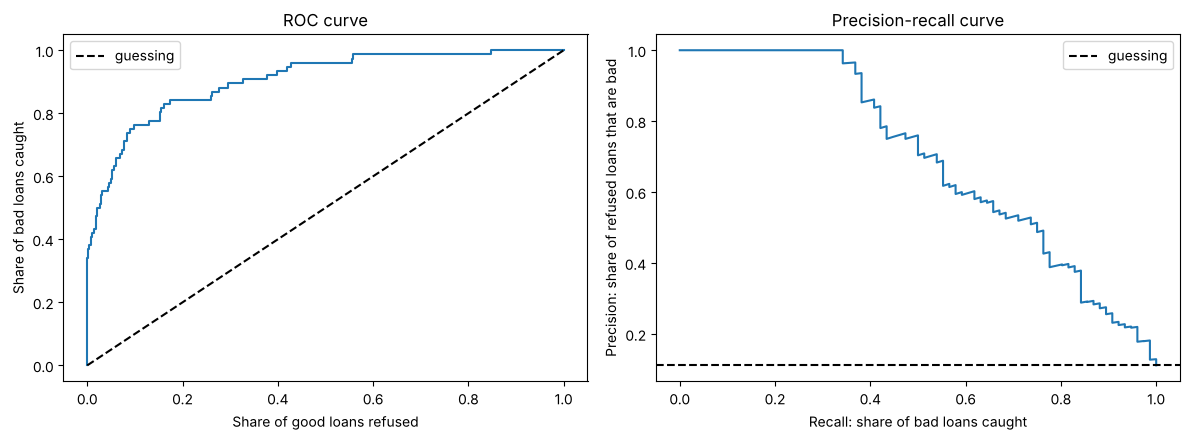

In [16]:
oof = cross_val_predict(rf, X, y, cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
                        method="predict_proba")[:, 1]
print(f"out-of-fold ROC-AUC: {roc_auc_score(y, oof):.3f}")

fpr, tpr, _ = roc_curve(y, oof)
precision, recall, _ = precision_recall_curve(y, oof)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
ax1.plot(fpr, tpr)
ax1.plot([0, 1], [0, 1], "k--", label="guessing")
ax1.set_xlabel("Share of good loans refused")
ax1.set_ylabel("Share of bad loans caught")
ax1.set_title("ROC curve")
ax1.legend()
ax2.plot(recall, precision)
ax2.axhline(y.mean(), color="k", linestyle="--", label="guessing")
ax2.set_xlabel("Recall: share of bad loans caught")
ax2.set_ylabel("Precision: share of refused loans that are bad")
ax2.set_title("Precision-recall curve")
ax2.legend()
plt.tight_layout()
plt.show()

In [17]:
rows = []
for threshold in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    refused = oof >= threshold
    rows.append({
        "threshold": threshold,
        "loans refused": refused.sum(),
        "bad caught": (refused & (y == 1)).sum(),
        "% of bad caught": round(100 * (refused & (y == 1)).sum() / y.sum(), 1),
        "good refused": (refused & (y == 0)).sum(),
        "% of refused that are bad": round(100 * (refused & (y == 1)).sum() / max(refused.sum(), 1), 1),
    })
pd.DataFrame(rows)

,threshold,loans refused,bad caught,% of bad caught,good refused,% of refused that are bad
0,0.2,290,69,90.8,221,23.8
1,0.3,198,64,84.2,134,32.3
2,0.4,144,59,77.6,85,41.0
3,0.5,103,54,71.1,49,52.4
4,0.6,70,43,56.6,27,61.4
5,0.7,48,36,47.4,12,75.0


### Choosing a threshold with costs

Which threshold is best depends on what mistakes cost. I don't have the bank's real figures, so I use **illustrative assumptions**:
- a bad loan that is approved loses **50% of the loan amount** (part is usually recovered)
- a good loan that is refused loses the profit it would have made, about **10% of the loan amount**

So missing a bad loan is about five times as costly as refusing a good one. The total cost is calculated with each loan's real amount.

cost if every loan is approved:     7.79 million CZK
cost with the simple rule:          5.03 million CZK
cost with the model, threshold 0.38: 2.74 million CZK


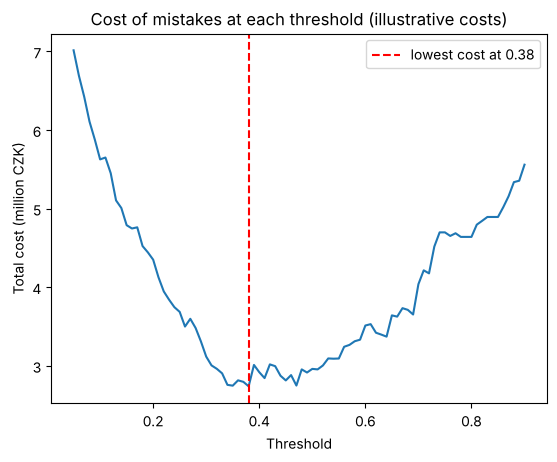

In [18]:
amount = features["amount"].values

def total_cost(threshold, loss_on_bad=0.5, profit_on_good=0.1):
    refused = oof >= threshold
    missed_bad = (~refused) & (y == 1)
    refused_good = refused & (y == 0)
    return loss_on_bad * amount[missed_bad].sum() + profit_on_good * amount[refused_good].sum()

thresholds = np.round(np.arange(0.05, 0.91, 0.01), 2)
costs = np.array([total_cost(t) for t in thresholds])
best = thresholds[costs.argmin()]

print(f"cost if every loan is approved:     {total_cost(1.01) / 1e6:.2f} million CZK")
print(f"cost with the simple rule:          {(0.5 * amount[(~rule) & (y == 1)].sum() + 0.1 * amount[rule & (y == 0)].sum()) / 1e6:.2f} million CZK")
print(f"cost with the model, threshold {best}: {costs.min() / 1e6:.2f} million CZK")

plt.plot(thresholds, costs / 1e6)
plt.axvline(best, color="red", linestyle="--", label=f"lowest cost at {best}")
plt.xlabel("Threshold")
plt.ylabel("Total cost (million CZK)")
plt.title("Cost of mistakes at each threshold (illustrative costs)")
plt.legend()
plt.show()

In [19]:
refused = oof >= best
print(f"at threshold {best}: refuse {refused.sum()} of {len(y)} loans, "
      f"catch {(refused & (y == 1)).sum()} of {y.sum()} bad loans, "
      f"refuse {(refused & (y == 0)).sum()} good loans")

at threshold 0.38: refuse 156 of 682 loans, catch 62 of 76 bad loans, refuse 94 good loans


- With these assumptions, the lowest cost is at a threshold of about **0.38**. The model then refuses or reviews **156 of 682 loans**, catches **62 of the 76 bad loans (82%)**, and refuses **94 good loans**.
- The total cost of mistakes falls from **7.8 million CZK** (approving everything) to **5.0 million** with the simple "never negative" rule, and to **2.7 million** with the model.
- The cost curve is fairly flat between about 0.33 and 0.50, so 0.38 shouldn't be taken as exact: any threshold in that range gives almost the same cost.
- The best threshold depends heavily on the cost assumptions. If refusing good customers were more expensive, the threshold would move up. In practice, the bank's real loss and profit figures should set it.
- A middle way would be to treat loans above the threshold as **"review by a person"** rather than automatic refusals: the 94 good loans among them could still be approved after a closer look.

## 10. Back to the segments

In step 3, Cash-only earners had a 42% bad-loan rate, but I warned that the segments use each customer's whole history, including the time after the loan. Does the risk still show up when the model only sees pre-loan data?

In [20]:
by_segment = pd.DataFrame({
    "segment": segments.set_index("account_id")["segment"].reindex(features.index).values,
    "is_bad": y,
    "predicted_risk": oof,
})
by_segment.groupby("segment").agg(
    loans=("is_bad", "size"),
    actual_pct_bad=("is_bad", "mean"),
    avg_predicted_risk=("predicted_risk", "mean"),
).round(3)

,loans,actual_pct_bad,avg_predicted_risk
segment,,,
Cash-only earners,135,0.422,0.489
Established savers,508,0.033,0.167
Low-income customers,39,0.051,0.299


Yes. Using only pre-loan data, the model gives **Cash-only earners** an average risk of 0.49, against 0.17 for Established savers, and they really do have the highest bad-loan rate (42%, against 3%). So the step 3 finding isn't only leakage: the warning signs are already visible before the loan.

Low-income customers get a fairly high predicted risk (0.30) but only 2 of their 39 loans went bad. With so few loans, it's hard to say whether the model is too cautious for this group. Pensioners have no loans at all.

## Summary of step 4

**Question:** can the bank predict which loans will go bad, using only what it knew when it granted them?

**Answer:** yes, quite well. A random forest built only on data from before each loan reaches a ROC-AUC of about **0.91** in cross-validation and **0.90** when trained on past years and tested on a later year. At a cost-based threshold it catches about **80% of bad loans**, and it cuts the estimated cost of lending mistakes by about **two thirds** compared with approving everything, and by about **half** compared with the simple "never negative" rule.

**What predicts a bad loan:**
- the balance **dropping low in the 90 days before the loan**
- a balance that **swings a lot**
- using **only cash**, and not paying bills by transfer
- having **already gone negative**

Income itself hardly matters: what separates good and bad borrowers is how they manage their money, not how much they earn.

**How the model was kept honest:**
- every feature uses only data from **before the loan date**, checked with `assert` statements
- **repeated stratified cross-validation** (25 folds) instead of one small test set, plus a **time-based test** on a later year
- a check that the **incomplete 1998 labels** don't change the result
- **age, gender and district left out** for fairness reasons

**Limitations:**
- Only **76 bad loans**: the results are uncertain by a few points, and a larger dataset would be needed before using a model like this for real decisions.
- The performance is **higher than credit models usually reach** on real data. This dataset showed several signs of being partly generated (the January pattern, transfers only on days 5–14, the perfect negative-balance split), so real-world performance would likely be lower.
- The costs used to pick the threshold are **assumptions**, not the bank's real figures.